In [ ]:
import torch
import torchvision
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
GPU available: True


In [ ]:

!pip install grad-cam


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=8f4068664ac0c5c8850d284520733ce47d7d051b01ee2debb75e24d0336ef73c
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [grad-cam]


# **New data set**


In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_dataset = torchvision.datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    transform=transform,
    download=True
)

test_dataset = torchvision.datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    transform=transform,
    download=True
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Number of breeds:", len(train_dataset.classes))
print("Example breeds:", train_dataset.classes[:5])

100%|██████████| 792M/792M [00:20<00:00, 39.3MB/s]
100%|██████████| 19.2M/19.2M [00:00<00:00, 19.2MB/s]


Training images: 3680
Testing images: 3669
Number of breeds: 37
Example breeds: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']


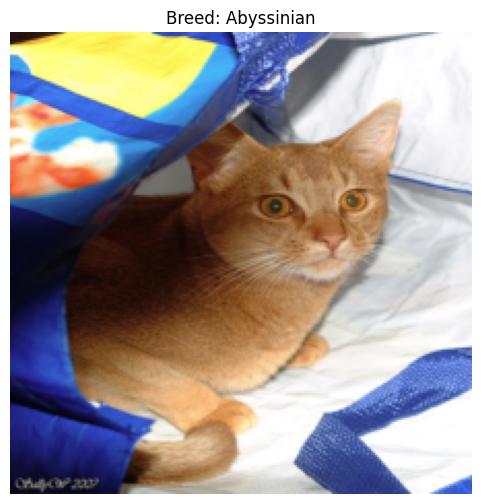

In [ ]:
image, label = train_dataset[0]

plt.figure(figsize=(6, 6))
plt.imshow(image.permute(1, 2, 0))
plt.title(f"Breed: {train_dataset.classes[label]}")
plt.axis("off")
plt.show()

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 115
Testing batches: 115


In [ ]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 37)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = CNN().to(device)

print("Model created successfully!")

Using device: cuda
Model created successfully!


In [ ]:
model = model.to(device)

In [ ]:
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Loss: {running_loss / len(train_loader):.4f}"
    )

Epoch [1/5], Loss: 3.5347
Epoch [2/5], Loss: 3.2924
Epoch [3/5], Loss: 3.0859
Epoch [4/5], Loss: 2.6718
Epoch [5/5], Loss: 1.8239


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 11.50%


In [ ]:
print("Number of classes:", len(train_dataset.classes))
print("First 10 class names:", train_dataset.classes[:10])

print("\nTraining labels:")
print([train_dataset[i][1] for i in range(10)])

print("\nTesting labels:")
print([test_dataset[i][1] for i in range(10)])

Number of classes: 37
First 10 class names: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair']

Training labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Testing labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [ ]:
model.eval()

images, labels = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1).cpu()

print("Actual labels:   ", labels[:20].tolist())
print("Predicted labels:", predictions[:20].tolist())

print("\nActual breeds:")
print([test_dataset.classes[i] for i in labels[:10].tolist()])

print("\nPredicted breeds:")
print([test_dataset.classes[i] for i in predictions[:10].tolist()])

Actual labels:    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Predicted labels: [20, 36, 35, 35, 27, 25, 35, 21, 18, 9, 24, 36, 9, 17, 23, 12, 17, 19, 33, 9]

Actual breeds:
['Abyssinian', 'Abyssinian', 'Abyssinian', 'Abyssinian', 'Abyssinian', 'Abyssinian', 'Abyssinian', 'Abyssinian', 'Abyssinian', 'Abyssinian']

Predicted breeds:
['Maine Coon', 'Yorkshire Terrier', 'Wheaten Terrier', 'Wheaten Terrier', 'Russian Blue', 'Pug', 'Wheaten Terrier', 'Miniature Pinscher', 'Keeshond', 'British Shorthair']


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    transform=train_transform,
    download=False
)

test_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    transform=test_transform,
    download=False
)

train_loader = DataLoader(
    train_dataset, batch_size=32,
    shuffle=True, num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=32,
    shuffle=False, num_workers=0
)

print("Datasets ready!")

Datasets ready!


In [ ]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Freeze the pretrained layers
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace the final layer for 37 breeds
model.fc = nn.Linear(model.fc.in_features, 37)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)

print("Pretrained ResNet18 is ready!")

Using device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 173MB/s]


Pretrained ResNet18 is ready!


In [ ]:
epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {running_loss / len(train_loader):.4f}"
    )

Epoch 1/5, Loss: 1.8874
Epoch 2/5, Loss: 0.7237
Epoch 3/5, Loss: 0.5057
Epoch 4/5, Loss: 0.3968
Epoch 5/5, Loss: 0.3488


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 86.37%


In [ ]:
import matplotlib.pyplot as plt
import torch

model.eval()

image, label = test_dataset[0]
input_tensor = image.unsqueeze(0).to(device)

with torch.no_grad():
    output = model(input_tensor)
    predicted_class = output.argmax(dim=1).item()

print("Actual breed:", test_dataset.classes[label])
print("Predicted breed:", test_dataset.classes[predicted_class])

Actual breed: Abyssinian
Predicted breed: Abyssinian


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("Grad-CAM installed successfully!")

Grad-CAM installed successfully!


Actual breed: Abyssinian
Predicted breed: Abyssinian


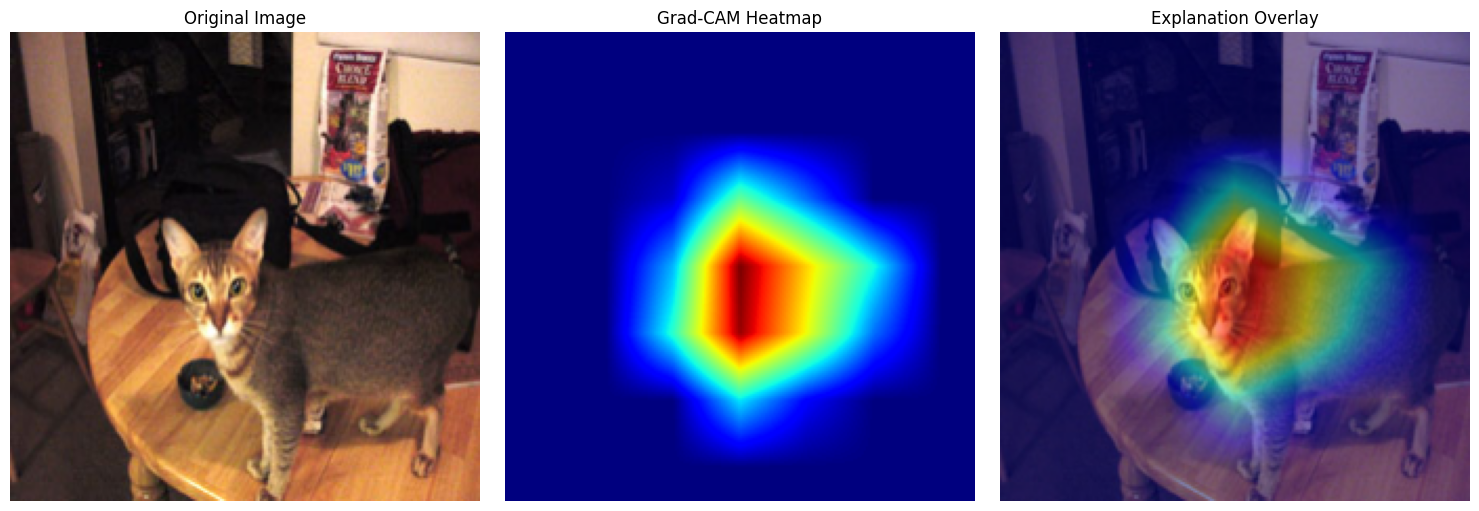

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Enable gradients for Grad-CAM
model.eval()
model.requires_grad_(True)

# Select a test image
image, label = test_dataset[0]
input_tensor = image.unsqueeze(0).to(device)

# Predict the breed
with torch.no_grad():
    output = model(input_tensor)
    predicted_class = output.argmax(dim=1).item()

print("Actual breed:", test_dataset.classes[label])
print("Predicted breed:", test_dataset.classes[predicted_class])

# Convert normalized image back to RGB
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

rgb_image = image.permute(1, 2, 0).numpy()
rgb_image = np.clip(rgb_image * std + mean, 0, 1)
rgb_image = rgb_image.astype(np.float32)

# Generate Grad-CAM
target_layers = [model.layer4[-1]]
targets = [ClassifierOutputTarget(predicted_class)]

with GradCAM(model=model, target_layers=target_layers) as cam:
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

# Create overlay
visualization = show_cam_on_image(
    rgb_image, grayscale_cam, use_rgb=True
)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(rgb_image)
axes[0].set_title("Original Image")

axes[1].imshow(grayscale_cam, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(visualization)
axes[2].set_title("Explanation Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

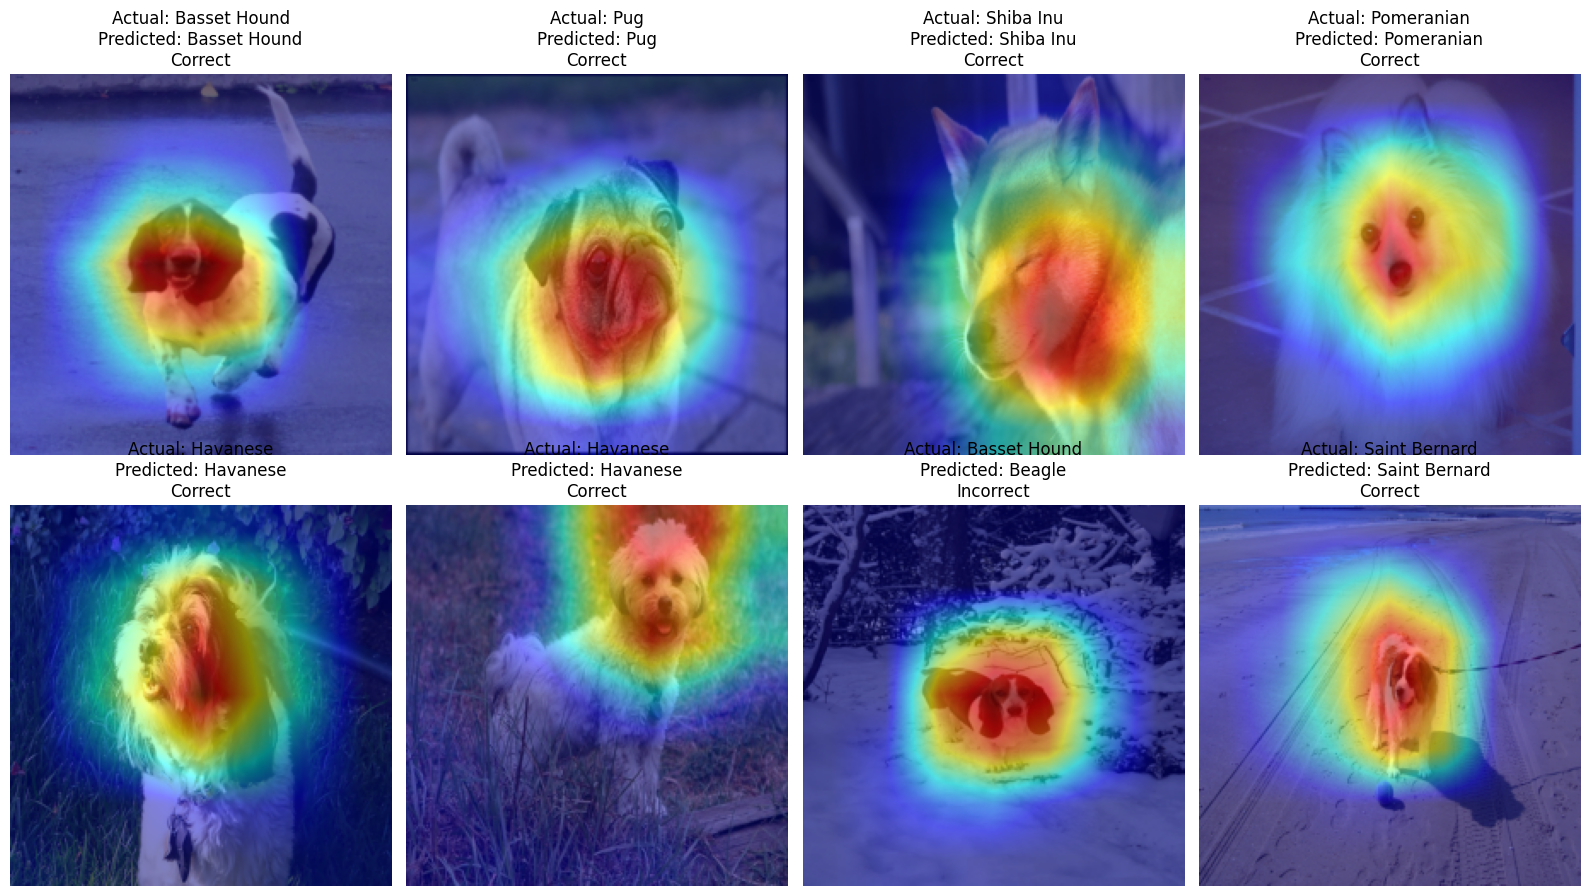

Correct predictions: 7/8


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

model.eval()
model.requires_grad_(True)

# Select 8 test images
rng = np.random.default_rng(42)
indices = rng.choice(len(test_dataset), size=8, replace=False)

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

target_layers = [model.layer4[-1]]
correct = 0

fig, axes = plt.subplots(2, 4, figsize=(16, 9))

with GradCAM(model=model, target_layers=target_layers) as cam:
    for ax, idx in zip(axes.flat, indices):
        image, label = test_dataset[int(idx)]
        input_tensor = image.unsqueeze(0).to(device)

        # Predict the breed
        with torch.no_grad():
            output = model(input_tensor)
            predicted_class = output.argmax(dim=1).item()

        # Generate explanation for the predicted breed
        targets = [ClassifierOutputTarget(predicted_class)]
        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=targets
        )[0]

        # Convert normalized image back to RGB
        rgb_image = image.permute(1, 2, 0).numpy()
        rgb_image = np.clip(rgb_image * std + mean, 0, 1)
        rgb_image = rgb_image.astype(np.float32)

        overlay = show_cam_on_image(
            rgb_image, grayscale_cam, use_rgb=True
        )

        is_correct = predicted_class == label
        correct += int(is_correct)

        ax.imshow(overlay)
        ax.set_title(
            f"Actual: {test_dataset.classes[label]}\n"
            f"Predicted: {test_dataset.classes[predicted_class]}\n"
            f"{'Correct' if is_correct else 'Incorrect'}"
        )
        ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Correct predictions: {correct}/8")

In [ ]:
from torchvision import datasets

localization_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types=["category", "segmentation"],
    download=False
)

print("Segmentation dataset loaded!")
print("Number of test images:", len(localization_dataset))

Segmentation dataset loaded!
Number of test images: 3669


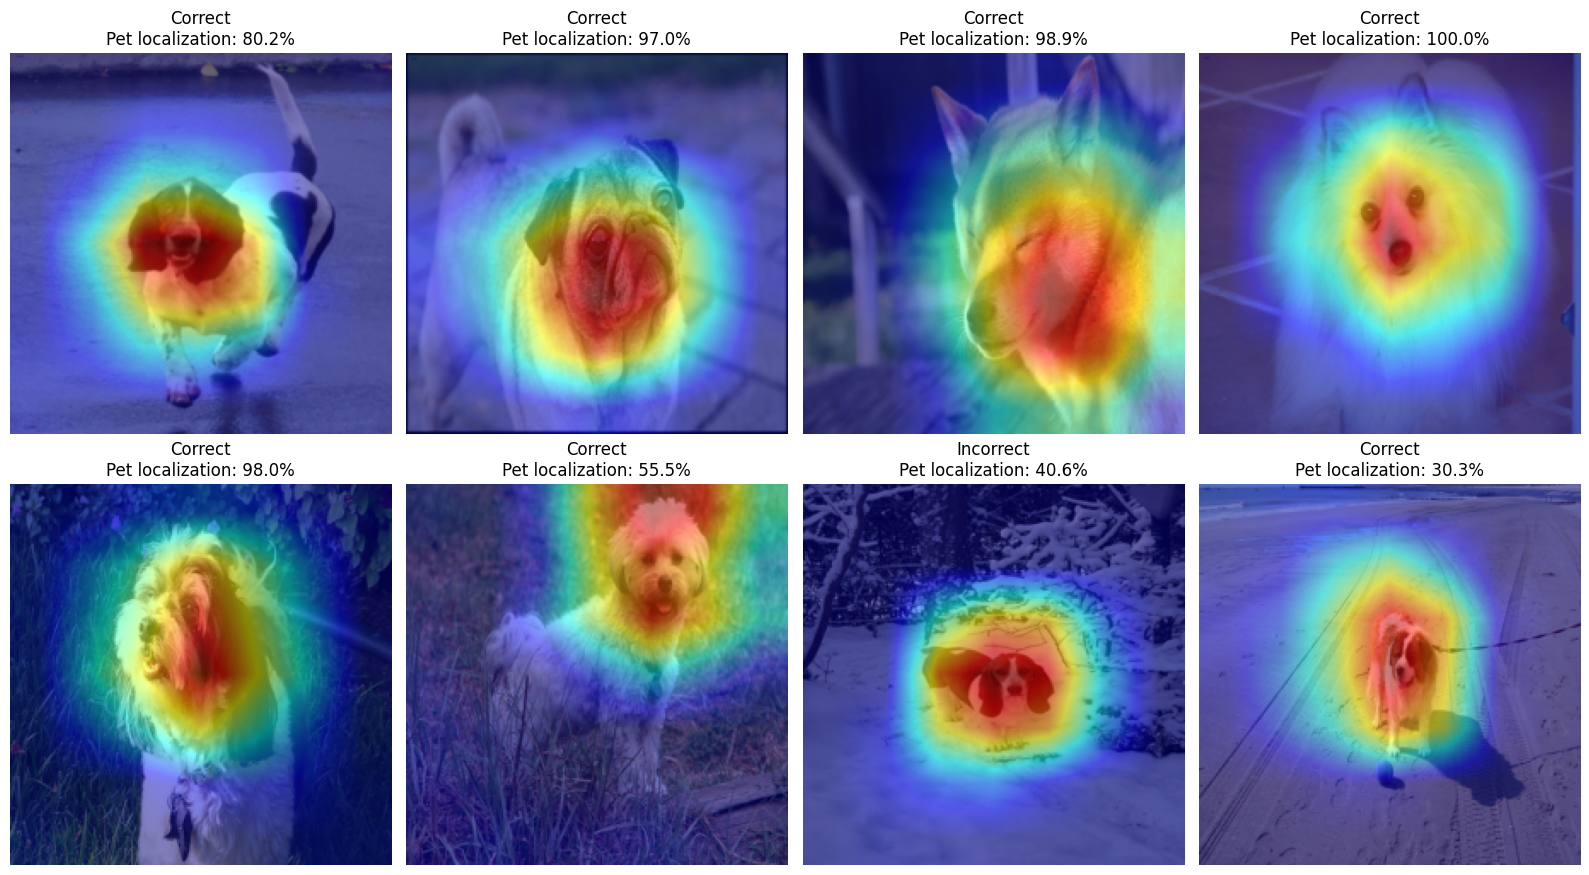

Mean pet localization score: 75.06%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

model.eval()
model.requires_grad_(True)

rng = np.random.default_rng(42)
indices = rng.choice(len(localization_dataset), 8, replace=False)

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

results = []
fig, axes = plt.subplots(2, 4, figsize=(16, 9))

with GradCAM(model=model, target_layers=[model.layer4[-1]]) as cam:
    for ax, idx in zip(axes.flat, indices):
        pil_image, (label, mask) = localization_dataset[int(idx)]

        # Convert PIL image to a normalized PyTorch tensor
        image = test_transform(pil_image)

        input_tensor = image.unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(input_tensor)
            pred = output.argmax(dim=1).item()

        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=[ClassifierOutputTarget(pred)]
        )[0]

        # Resize the segmentation mask to match the image
        mask = mask.resize(
            (224, 224), resample=Image.Resampling.NEAREST
        )
        mask = np.array(mask)

        # Oxford-IIIT Pet trimap: 1 = pet, 2 = background, 3 = boundary
        pet_mask = (mask == 1) | (mask == 3)

        # Select the 20% highest-activation pixels
        threshold = np.percentile(grayscale_cam, 80)
        high_activation = grayscale_cam >= threshold

        # What percentage of highly activated pixels lie on the pet?
        localization_score = (
            pet_mask[high_activation].mean() * 100
            if high_activation.any() else 0
        )

        rgb = image.permute(1, 2, 0).numpy()
        rgb = np.clip(rgb * std + mean, 0, 1).astype(np.float32)

        overlay = show_cam_on_image(
            rgb, grayscale_cam, use_rgb=True
        )

        results.append(localization_score)

        ax.imshow(overlay)
        ax.set_title(
            f"{'Correct' if pred == label else 'Incorrect'}\n"
            f"Pet localization: {localization_score:.1f}%"
        )
        ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Mean pet localization score: {np.mean(results):.2f}%")

# **Testing Our Own Image**

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 6735e079d0977523978416.avif to 6735e079d0977523978416.avif


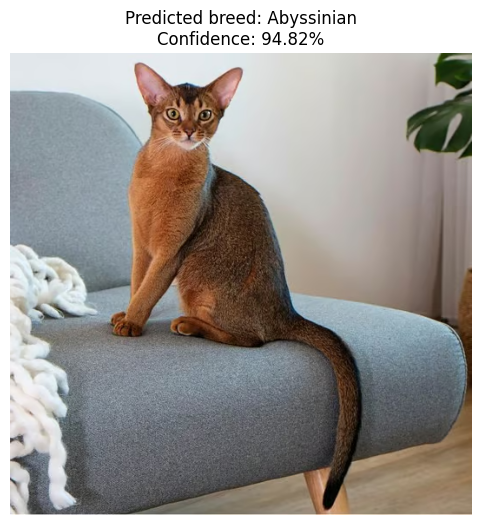

Predicted breed: Abyssinian
Model confidence: 94.82%


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import torch

# Get the uploaded filename
filename = next(iter(uploaded))

# Open and prepare the image
pil_image = Image.open(filename).convert("RGB")
input_tensor = test_transform(pil_image).unsqueeze(0).to(device)

# Predict the breed
model.eval()

with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)[0]
    predicted_class = probabilities.argmax().item()
    confidence = probabilities[predicted_class].item() * 100

# Display the result
plt.figure(figsize=(6, 6))
plt.imshow(pil_image)
plt.title(
    f"Predicted breed: {train_dataset.classes[predicted_class]}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

print("Predicted breed:", train_dataset.classes[predicted_class])
print(f"Model confidence: {confidence:.2f}%")

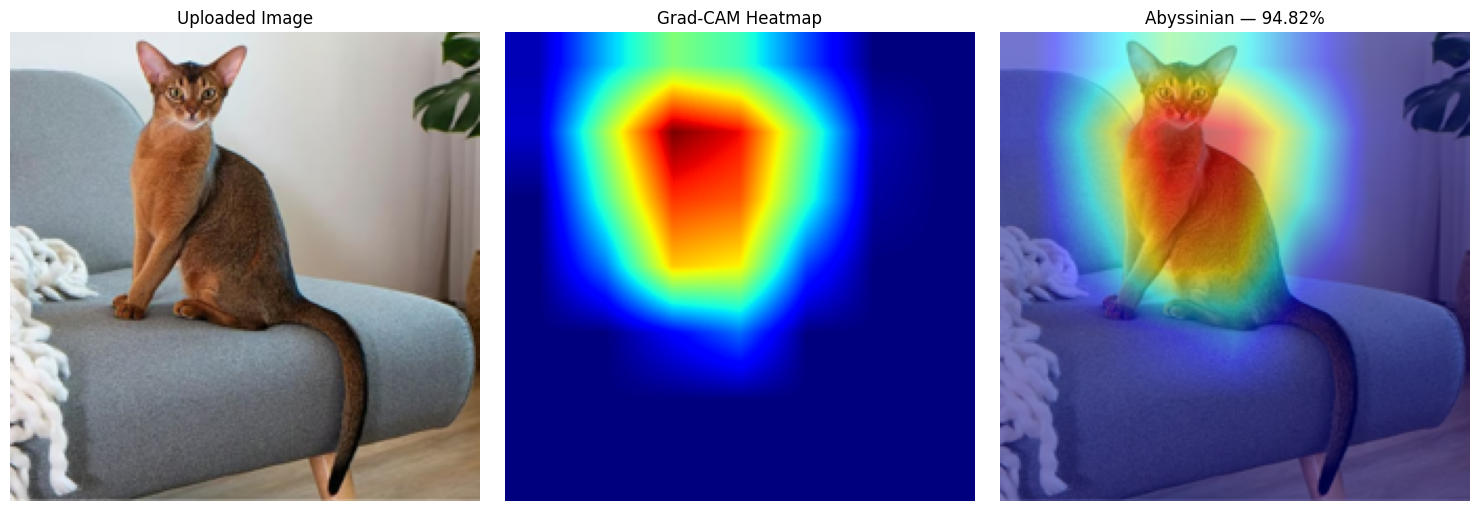

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Prepare the uploaded image
rgb_image = np.array(pil_image.resize((224, 224))).astype(np.float32) / 255.0

target_layers = [model.layer4[-1]]
targets = [ClassifierOutputTarget(predicted_class)]

with GradCAM(model=model, target_layers=target_layers) as cam:
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

overlay = show_cam_on_image(
    rgb_image, grayscale_cam, use_rgb=True
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(rgb_image)
axes[0].set_title("Uploaded Image")

axes[1].imshow(grayscale_cam, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title(
    f"{train_dataset.classes[predicted_class]} — {confidence:.2f}%")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

**List of all Breeds**

In [ ]:
for i, breed in enumerate(train_dataset.classes, start=1):
    print(f"{i}. {breed}")

print("\nTotal breeds:", len(train_dataset.classes))

1. Abyssinian
2. American Bulldog
3. American Pit Bull Terrier
4. Basset Hound
5. Beagle
6. Bengal
7. Birman
8. Bombay
9. Boxer
10. British Shorthair
11. Chihuahua
12. Egyptian Mau
13. English Cocker Spaniel
14. English Setter
15. German Shorthaired
16. Great Pyrenees
17. Havanese
18. Japanese Chin
19. Keeshond
20. Leonberger
21. Maine Coon
22. Miniature Pinscher
23. Newfoundland
24. Persian
25. Pomeranian
26. Pug
27. Ragdoll
28. Russian Blue
29. Saint Bernard
30. Samoyed
31. Scottish Terrier
32. Shiba Inu
33. Siamese
34. Sphynx
35. Staffordshire Bull Terrier
36. Wheaten Terrier
37. Yorkshire Terrier

Total breeds: 37


# **Save the trained model weights and class names**

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
import torch
import json

# Save model weights
torch.save(model.state_dict(), "pet_breed_model.pth")

# Save class names
with open("class_names.json", "w") as f:
    json.dump(train_dataset.classes, f, indent=4)

print("Model weights and class names saved successfully!")

Model weights and class names saved successfully!


In [ ]:
from google.colab import files

files.download("pet_breed_model.pth")
files.download("class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import torch
import torch.nn as nn
import json
from torchvision.models import resnet18

# Load class names
with open("class_names.json", "r") as f:
    class_names = json.load(f)

# Recreate model architecture
model = resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(class_names))

# Load trained weights
model.load_state_dict(
    torch.load("pet_breed_model.pth", map_location=device, weights_only=True)
)

model = model.to(device)
model.eval()

print("Model loaded successfully!")
print("Total classes:", len(class_names))

Model loaded successfully!
Total classes: 37


In [ ]:
import os

print("Model file exists:", os.path.exists("pet_breed_model.pth"))
print("Class names file exists:", os.path.exists("class_names.json"))
print("Number of breeds:", len(class_names))

Model file exists: True
Class names file exists: True
Number of breeds: 37


# **Create a confusion matrix and per-class evaluation**

In [ ]:
import torch
import numpy as np

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Predictions collected:", len(all_predictions))
print("Actual labels collected:", len(all_labels))

Predictions collected: 3669
Actual labels collected: 3669


**Generate the confusion matrix**

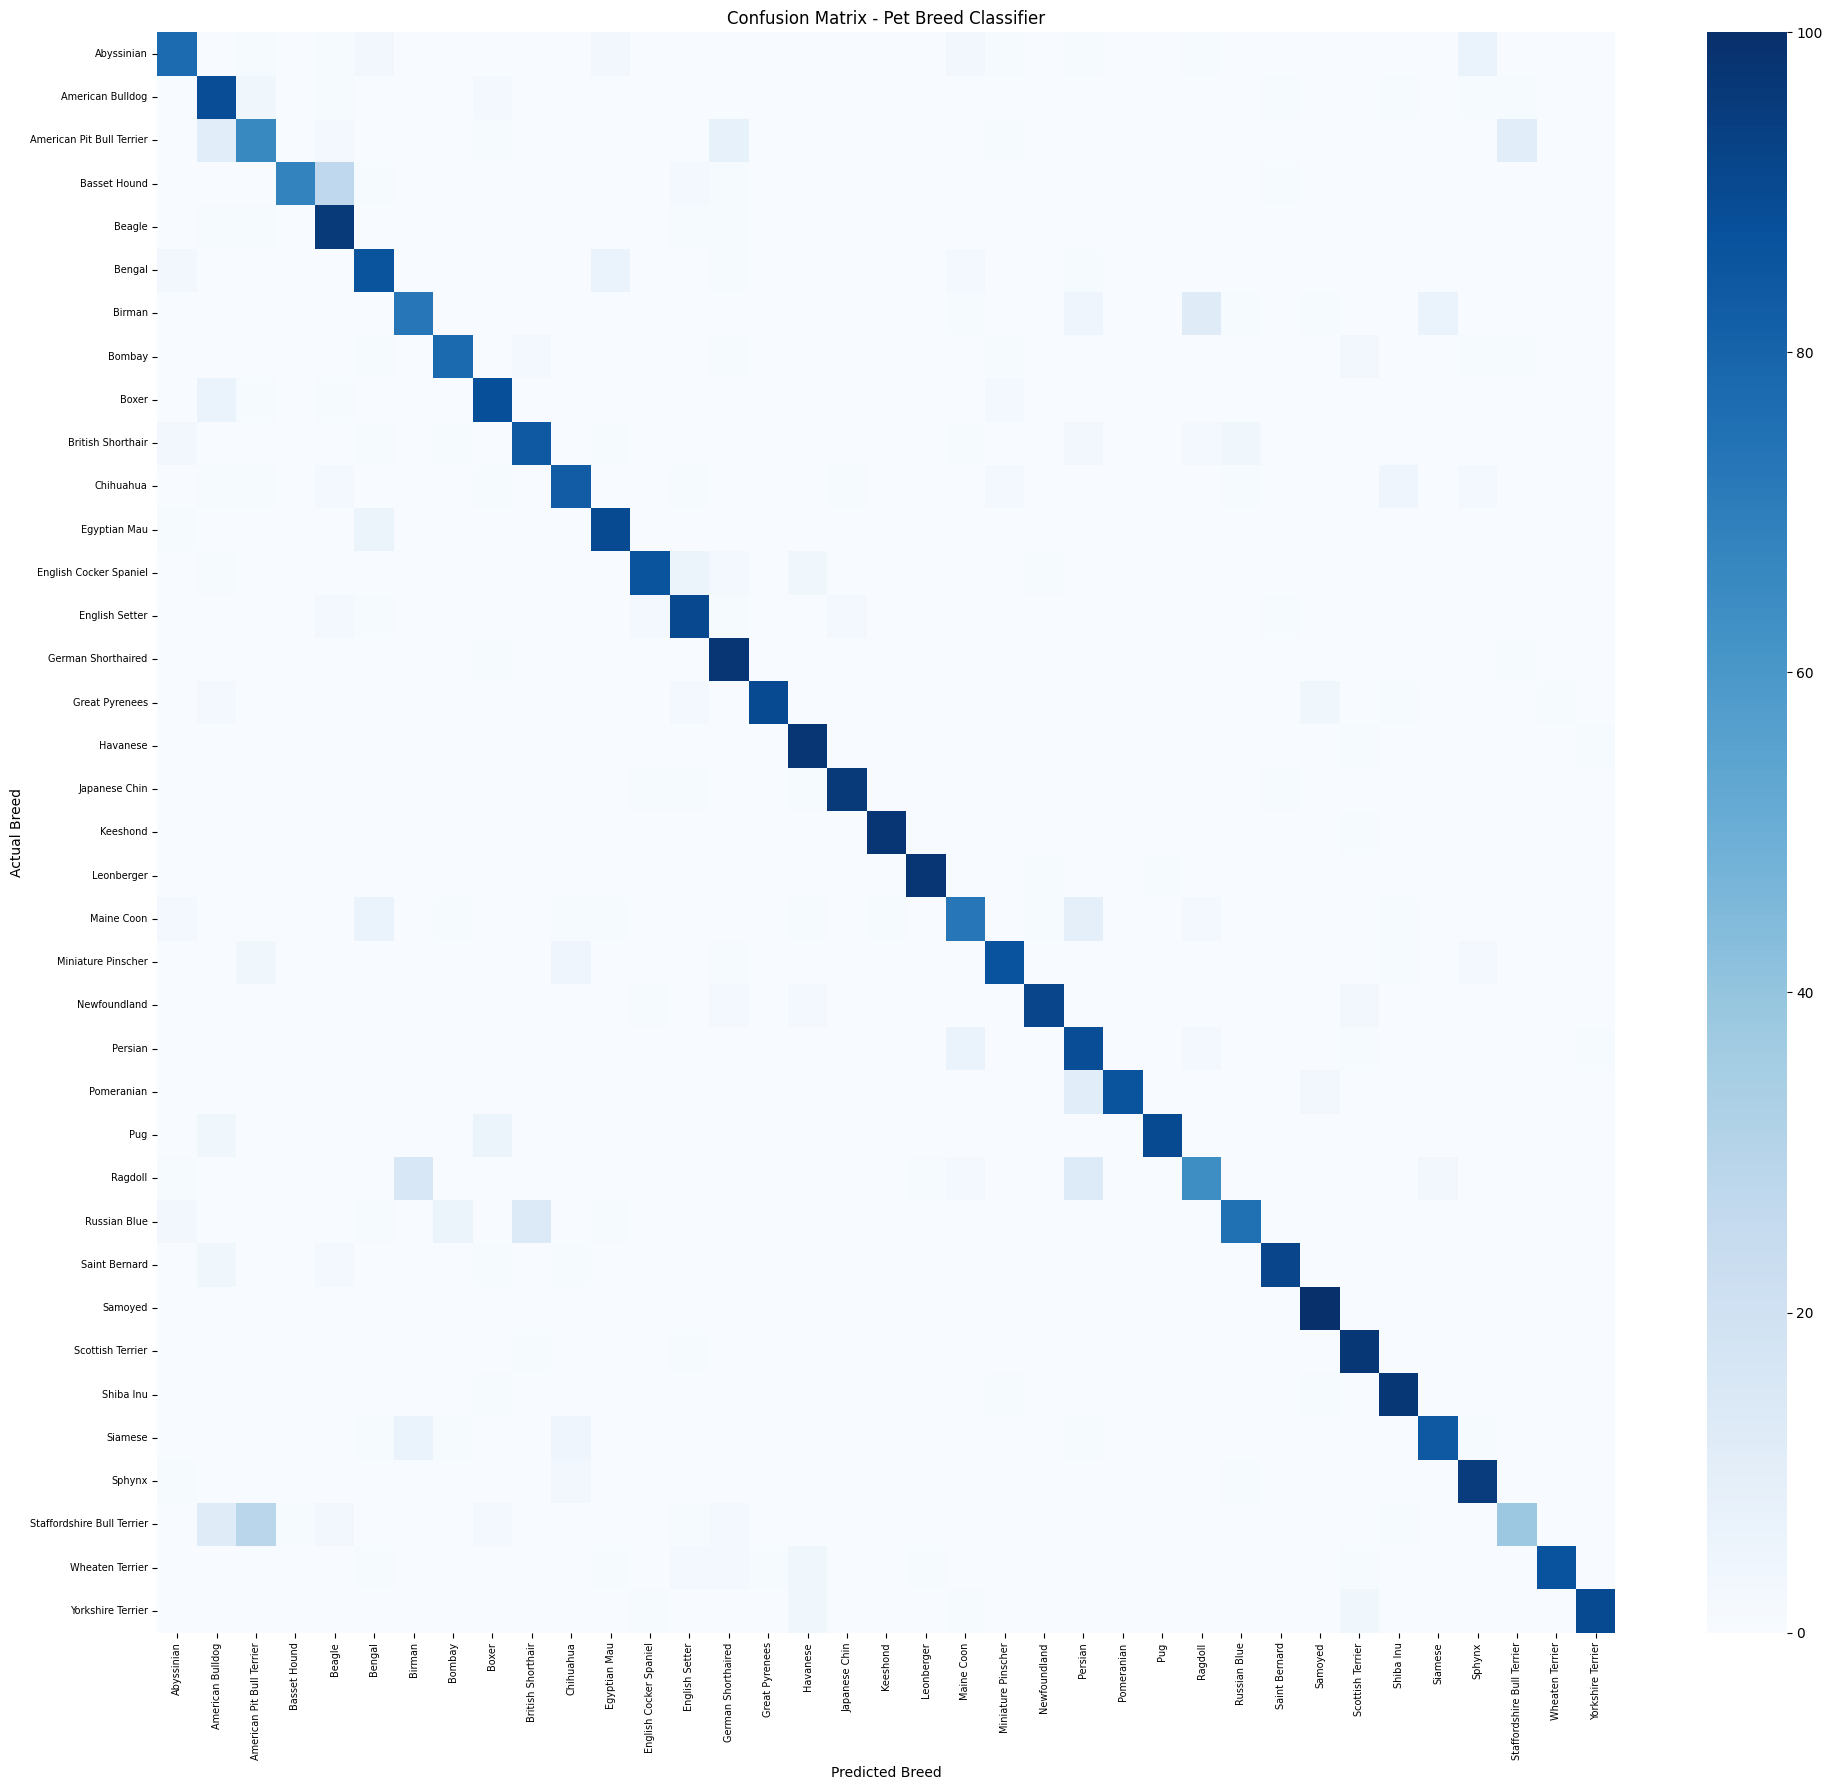

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(20, 18))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.xlabel("Predicted Breed")
plt.ylabel("Actual Breed")
plt.title("Confusion Matrix - Pet Breed Classifier")

plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)

plt.tight_layout()
plt.show()

**Per-class evaluation**

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    all_labels,
    all_predictions,
    target_names=train_dataset.classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

# Display individual breed results
breed_results = report_df.iloc[:len(train_dataset.classes)]

print(breed_results.round(3))

                            precision  recall  f1-score  support
Abyssinian                      0.846   0.786     0.815     98.0
American Bulldog                0.674   0.890     0.767    100.0
American Pit Bull Terrier       0.617   0.660     0.638    100.0
Basset Hound                    0.986   0.680     0.805    100.0
Beagle                          0.701   0.960     0.810    100.0
Bengal                          0.789   0.860     0.823    100.0
Birman                          0.760   0.730     0.745    100.0
Bombay                          0.897   0.886     0.891     88.0
Boxer                           0.854   0.889     0.871     99.0
British Shorthair               0.832   0.840     0.836    100.0
Chihuahua                       0.847   0.830     0.838    100.0
Egyptian Mau                    0.865   0.928     0.896     97.0
English Cocker Spaniel          0.945   0.860     0.901    100.0
English Setter                  0.843   0.910     0.875    100.0
German Shorthaired       

In [ ]:
print("Overall Evaluation:\n")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=train_dataset.classes,
    zero_division=0
))

Overall Evaluation:

                            precision    recall  f1-score   support

                Abyssinian       0.85      0.79      0.81        98
          American Bulldog       0.67      0.89      0.77       100
 American Pit Bull Terrier       0.62      0.66      0.64       100
              Basset Hound       0.99      0.68      0.80       100
                    Beagle       0.70      0.96      0.81       100
                    Bengal       0.79      0.86      0.82       100
                    Birman       0.76      0.73      0.74       100
                    Bombay       0.90      0.89      0.89        88
                     Boxer       0.85      0.89      0.87        99
         British Shorthair       0.83      0.84      0.84       100
                 Chihuahua       0.85      0.83      0.84       100
              Egyptian Mau       0.87      0.93      0.90        97
    English Cocker Spaniel       0.95      0.86      0.90       100
            English Setter

**Save evaluation results**

In [ ]:
breed_results.to_csv("per_class_evaluation.csv")

from google.colab import files
files.download("per_class_evaluation.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Prepare Grad-CAM**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

model.eval()
model.requires_grad_(True)

target_layers = [model.layer4[-1]]

**Evaluate Grad-CAM on 100 images**

In [ ]:
from torchvision import datasets
from torch.utils.data import DataLoader

localization_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types=["category", "segmentation"],
    download=False
)

localization_loader = DataLoader(
    localization_dataset,
    batch_size=1,
    shuffle=False
)

In [ ]:
from PIL import Image

results = []

num_images = min(100, len(localization_dataset))

with GradCAM(
    model=model,
    target_layers=target_layers
) as cam:

    for i in range(num_images):

        pil_image, (label, mask) = localization_dataset[i]

        # Preprocess image
        image_tensor = test_transform(pil_image)
        input_tensor = image_tensor.unsqueeze(0).to(device)

        # Get prediction
        with torch.no_grad():
            output = model(input_tensor)
            predicted_class = output.argmax(dim=1).item()
            confidence = torch.softmax(output, dim=1)[0, predicted_class].item()

        # Generate Grad-CAM
        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=[ClassifierOutputTarget(predicted_class)]
        )[0]

        # Resize the segmentation mask to match the 224x224 input size
        mask = mask.resize((224, 224), resample=Image.Resampling.NEAREST)
        mask = np.array(mask)
        pet_mask = (mask == 1) | (mask == 3)

        # Select top 20% Grad-CAM activations
        threshold = np.percentile(grayscale_cam, 80)
        important_regions = grayscale_cam >= threshold

        # Calculate pet localization score
        intersection = np.logical_and(important_regions, pet_mask).sum()
        localization_score = intersection / important_regions.sum()

        results.append({
            "image": i,
            "actual_breed": train_dataset.classes[label],
            "predicted_breed": train_dataset.classes[predicted_class],
            "correct": predicted_class == label,
            "confidence": confidence,
            "localization_score": localization_score
        })

        if (i + 1) % 10 == 0:
            print(f"Processed {i + 1}/{num_images} images")

print("Grad-CAM evaluation completed!")

Processed 10/100 images
Processed 20/100 images
Processed 30/100 images
Processed 40/100 images
Processed 50/100 images
Processed 60/100 images
Processed 70/100 images
Processed 80/100 images
Processed 90/100 images
Processed 100/100 images
Grad-CAM evaluation completed!


**Calculate average localization score**

In [ ]:
results_df = pd.DataFrame(results)

print("Number of images:", len(results_df))

print(
    "Mean pet localization score:",
    round(results_df["localization_score"].mean() * 100, 2),
    "%"
)

print(
    "Classification accuracy:",
    round(results_df["correct"].mean() * 100, 2),
    "%"
)

Number of images: 100
Mean pet localization score: 79.75 %
Classification accuracy: 79.0 %


**Visualize Grad-CAM examples**

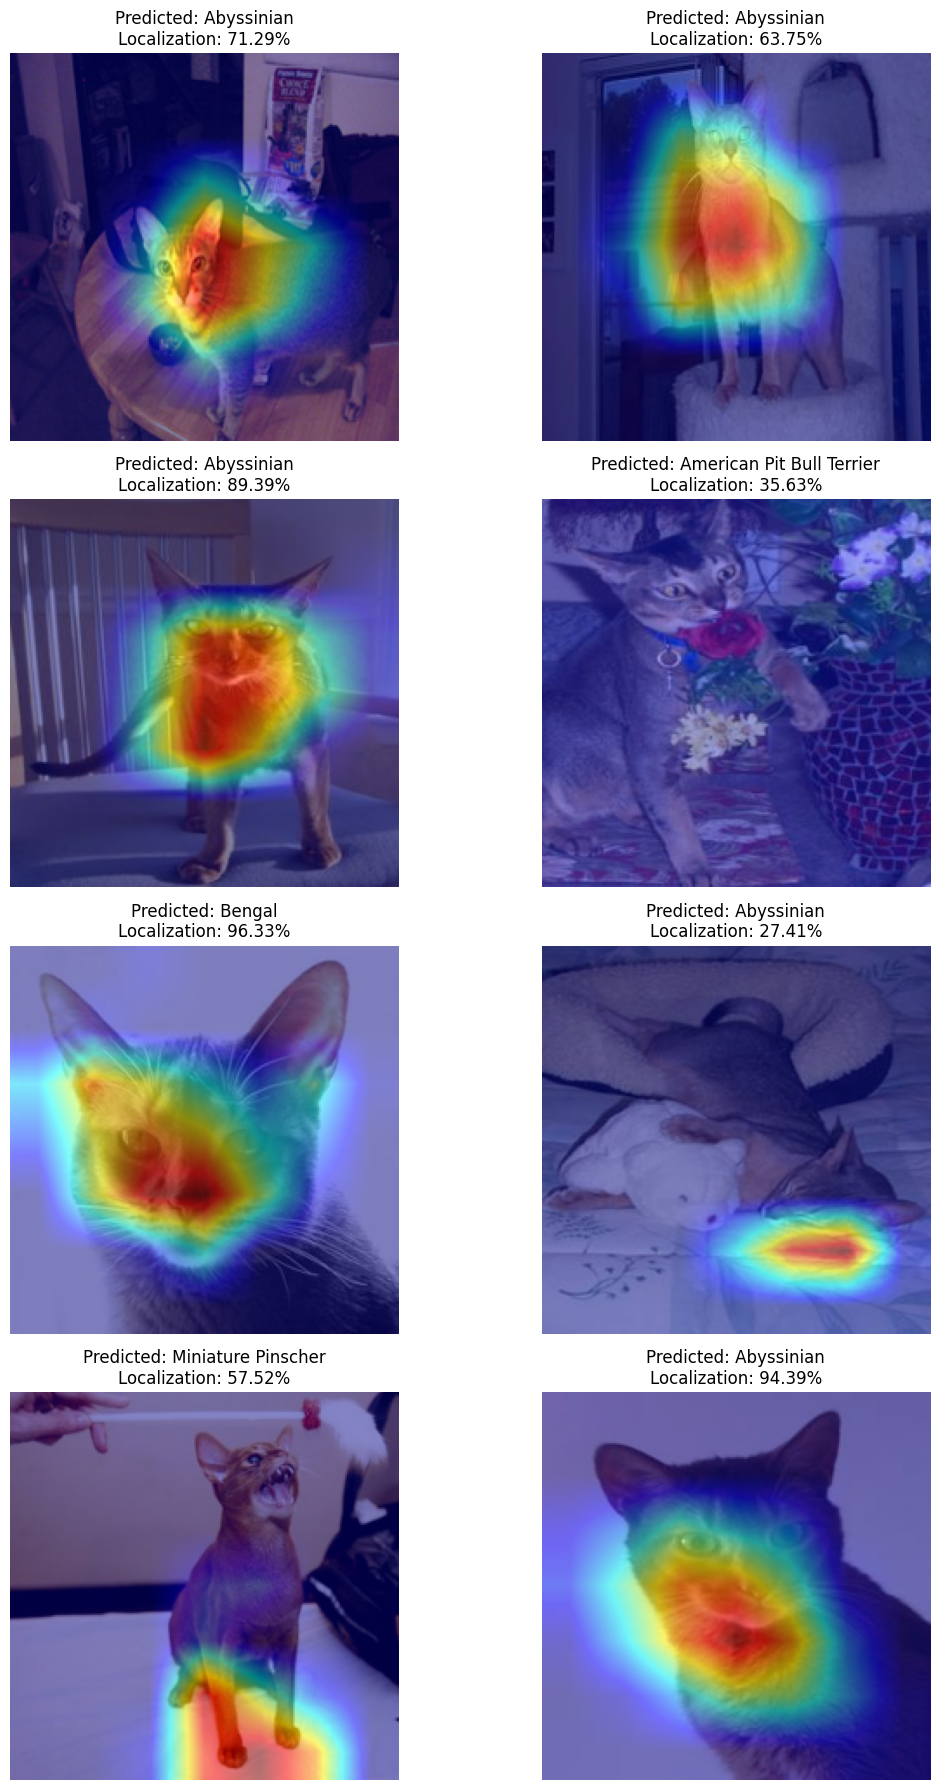

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(12, 18))

with GradCAM(
    model=model,
    target_layers=target_layers
) as cam:

    for i, ax in enumerate(axes.flat):

        pil_image, (label, mask) = localization_dataset[i]

        image_tensor = test_transform(pil_image)
        input_tensor = image_tensor.unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(input_tensor)
            predicted_class = output.argmax(dim=1).item()

        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=[ClassifierOutputTarget(predicted_class)]
        )[0]

        rgb_image = np.array(
            pil_image.resize((224, 224))
        ).astype(np.float32) / 255.0

        overlay = show_cam_on_image(
            rgb_image,
            grayscale_cam,
            use_rgb=True
        )

        ax.imshow(overlay)

        breed = train_dataset.classes[predicted_class]

        ax.set_title(
            f"Predicted: {breed}\n"
            f"Localization: {results_df.iloc[i]['localization_score']:.2%}"
        )

        ax.axis("off")

plt.tight_layout()
plt.show()

**Save results**

In [ ]:
results_df.to_csv("gradcam_evaluation.csv", index=False)

from google.colab import files
files.download("gradcam_evaluation.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Prepare the evaluation dataset**

In [ ]:
from torchvision import datasets

localization_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types=["category", "segmentation"],
    download=False
)

print("Total test images:", len(localization_dataset))

Total test images: 3669


**Run localization evaluation on 100 images**

In [ ]:
import torch
import numpy as np
import pandas as pd

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

model.eval()
model.requires_grad_(True)

results = []
num_images = min(100, len(localization_dataset))

with GradCAM(
    model=model,
    target_layers=[model.layer4[-1]]
) as cam:

    for i in range(num_images):

        pil_image, (label, mask) = localization_dataset[i]

        # Preprocess image
        image_tensor = test_transform(pil_image)
        input_tensor = image_tensor.unsqueeze(0).to(device)

        # Predict breed
        with torch.no_grad():
            output = model(input_tensor)
            predicted_class = output.argmax(dim=1).item()
            confidence = torch.softmax(output, dim=1)[0, predicted_class].item()

        # Generate Grad-CAM
        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=[ClassifierOutputTarget(predicted_class)]
        )[0]

        # Get pet segmentation mask
        mask = np.array(mask.resize((224, 224)))
        pet_mask = np.isin(mask, [1, 3])

        # Select top 20% activation regions
        threshold = np.percentile(grayscale_cam, 80)
        important_regions = grayscale_cam >= threshold

        # Calculate localization score
        score = (
            np.logical_and(important_regions, pet_mask).sum()
            / important_regions.sum()
        )

        results.append({
            "image": i,
            "actual_breed": train_dataset.classes[label],
            "predicted_breed": train_dataset.classes[predicted_class],
            "correct": predicted_class == label,
            "confidence": confidence,
            "localization_score": score
        })

        if (i + 1) % 10 == 0:
            print(f"Completed {i + 1}/{num_images}")

print("Evaluation completed!")

Completed 10/100
Completed 20/100
Completed 30/100
Completed 40/100
Completed 50/100
Completed 60/100
Completed 70/100
Completed 80/100
Completed 90/100
Completed 100/100
Evaluation completed!


**Calculate final results**

In [ ]:
results_df = pd.DataFrame(results)

mean_score = results_df["localization_score"].mean() * 100
accuracy = results_df["correct"].mean() * 100

print(f"Images evaluated: {len(results_df)}")
print(f"Mean localization score: {mean_score:.2f}%")
print(f"Classification accuracy: {accuracy:.2f}%")

Images evaluated: 100
Mean localization score: 78.93%
Classification accuracy: 79.00%


**Compare correct and incorrect predictions**

In [ ]:
print(
    results_df.groupby("correct")["localization_score"]
    .mean()
    .mul(100)
    .rename(index={True: "Correct predictions", False: "Incorrect predictions"})
)

correct
Incorrect predictions    64.250824
Correct predictions      82.826935
Name: localization_score, dtype: float64


In [ ]:
results_df.to_csv("gradcam_localization_100.csv", index=False)

from google.colab import files
files.download("gradcam_localization_100.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>